In [ ]:
import pandas as pd 
import numpy as np
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.impute import SimpleImputer,KNNImputer,
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [4]:


df = pd.read_csv("stroke_zaj1.csv",sep=';')


## dane intro 

- response variable to stroke

In [5]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67,0,1,Yes,Private,Urban,"228,69","36,6",formerly smoked,1
1,Male,80,0,1,Yes,Private,Rural,"105,92","32,5",never smoked,1
2,Female,49,0,0,Yes,Private,NaN,"171,23","34,4",smokes,1
3,Female,79,1,0,Yes,Self-employed,Rural,"174,12",24,never smoked,1
4,Male,81,0,0,Yes,Private,Urban,"186,21",29,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
607,Male,48,0,0,Yes,Private,Rural,NaN,"34,6",never smoked,0
608,Female,62,0,0,Yes,Private,Urban,"60,2","27,7",formerly smoked,0
609,Male,69,1,0,No,NaN,Urban,"75,95","28,6",never smoked,0
610,Female,54,0,0,Yes,Private,Urban,"75,09","38,9",formerly smoked,0


In [9]:
df.shape



(612, 11)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   gender             612 non-null    str  
 1   age                612 non-null    int64
 2   hypertension       612 non-null    int64
 3   heart_disease      612 non-null    int64
 4   ever_married       612 non-null    str  
 5   work_type          557 non-null    str  
 6   Residence_type     552 non-null    str  
 7   avg_glucose_level  568 non-null    str  
 8   bmi                549 non-null    str  
 9   smoking_status     612 non-null    str  
 10  stroke             612 non-null    int64
dtypes: int64(4), str(7)
memory usage: 52.7 KB


In [32]:
df.describe()


,age,hypertension,heart_disease,stroke
count,612.000000,612.000000,612.000000,612.000000
mean,52.632353,0.158497,0.096405,0.341503
std,20.709916,0.365505,0.295388,0.474602
min,5.000000,0.000000,0.000000,0.000000
25%,39.000000,0.000000,0.000000,0.000000
50%,54.000000,0.000000,0.000000,0.000000
75%,70.000000,0.000000,0.000000,1.000000
max,82.000000,1.000000,1.000000,1.000000


In [18]:
df.dtypes


gender                 str
age                  int64
hypertension         int64
heart_disease        int64
ever_married           str
work_type              str
Residence_type         str
avg_glucose_level      str
bmi                    str
smoking_status         str
stroke               int64
dtype: object

In [20]:

df.isna().sum()



gender                0
age                   0
hypertension          0
heart_disease         0
ever_married          0
work_type            55
Residence_type       60
avg_glucose_level    44
bmi                  63
smoking_status        0
stroke                0
dtype: int64

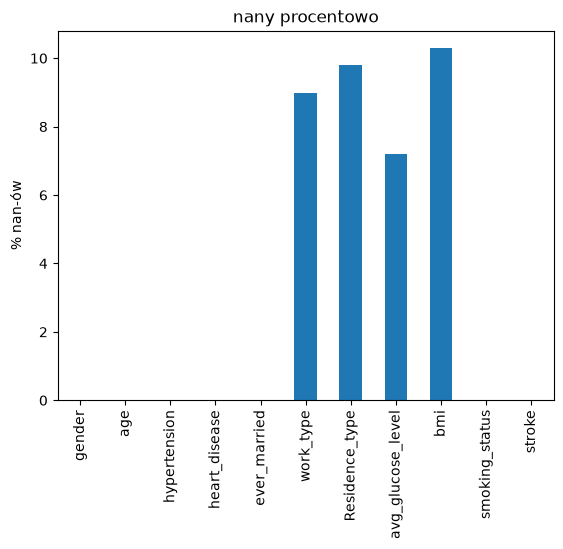

In [34]:
(df.isna().mean() * 100).round(2).plot(kind='bar') # y axis to są procenty 

plt.title("nany procentowo")

plt.ylabel("% nan-ów")

plt.show()

## podzial danych 

In [26]:

X = df.drop(columns=["stroke"])
y = df["stroke"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,  test_size=0.2, random_state=42, stratify=y )

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

In [ ]:

print(f"Test: ---> {y_train.value_counts(normalize=True)}  ") 

print(f"Test: ---> {y_test.value_counts(normalize=True)}  ")

Test: ---> stroke
0    0.658487
1    0.341513
Name: proportion, dtype: float64  
Test: ---> stroke
0    0.658537
1    0.341463
Name: proportion, dtype: float64  


- podział danych klasy y jest +- równy, dlatego używamy stratify ( bez niej proporcji podzialu nie kontrolujemy i będą split-dependent)

## Imputowanie zmiennych przed i po